# R7-A1 - Brazo del agente de optimización: etapa 1 y confirmación

**Objetivo.** Aplicar de forma literal las reglas escritas de antemano en `results/classification/r7_optimizacion/agente/protocolo_agente.json` (con la enmienda E1) a las 45 corridas de la etapa 1: nueve candidatas sobre ConvNeXt-Tiny con imagen completa, cinco folds de E2 y semilla 42, frente a las referencias B0 y B2 (corridas existentes de `robustez_e2`). El notebook elige el finalista con `seleccion_del_finalista` y genera, solo si lo hay, los 30 comandos de la confirmación. La sección 8 aplica la `regla_de_eleccion` a las 30 corridas de la confirmación del finalista (semillas 43 y 44) frente a B0 y B2. No añade reglas ni usa test.

**Diseño.** Cada candidata cambia un solo factor respecto de B0; no hay combinaciones. Todas conservan el criterio de checkpoint (máximo `val_roc_auc`), α = 1.0 y el early stopping por pérdida ponderada de validation.

| Candidata | Factor | Flags |
|---|---|---|
| `a01_lr5e5`, `a02_lr2e4` | learning rate pico | `--learning-rate 5e-5` / `2e-4` |
| `a03_cosine` | calentamiento y coseno | `--lr-schedule warmup_cosine --warmup-epochs 1 --cosine-epochs 15 --lr-min 1e-6` |
| `a04_llrd08` | decaimiento por capa | `--layer-decay 0.8` |
| `a05_dp03` | stochastic depth | `--drop-path-rate 0.3` |
| `a06_ls01` | label smoothing uniforme (E1) | `--label-smoothing 0.1` |
| `a08_augmod` | intensidad del aumento | `--augmentation moderate` |
| `a09_res288` | resolución | `--image-size 288` |
| `a10_ema099` | EMA de pesos | `--ema-decay 0.99` |

E2 es estratificada y no por paciente, y el AP del finalista es el máximo de nueve estimaciones ruidosas: está sesgado al alza. La estimación válida del desempeño es la de test en R8.

## 1. Configuración

In [1]:
from pathlib import Path
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.classification import agente_etapa1_analysis as a1  # toda la lógica del análisis está en este módulo

AGENT_DIR = PROJECT_ROOT / a1.AGENT_REL
ANALYSIS_DIR = AGENT_DIR / a1.ANALYSIS_NAME
OUTPUTS = {key: ANALYSIS_DIR / name for key, name in a1.OUTPUT_FILES.items()}

PROTOCOL, PROTOCOL_PATH = a1.load_agent_protocol(PROJECT_ROOT)
CANDIDATES = a1.candidate_table(PROTOCOL)  # en el orden del protocolo
RUNS = a1.stage1_runs(PROTOCOL)
CONFIGS = list(CANDIDATES) + ["b0", "b2"]
N_FOLDS = a1.N_FOLDS

COLORS = {"b0": "#0072B2", "b2": "#009E73"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def require(condition, message):
    if not condition:
        raise AssertionError(message)


print(f"Protocolo: {PROTOCOL_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Estado declarado: {PROTOCOL['estado']}")
print(f"Enmiendas: {[e['id'] for e in PROTOCOL['enmiendas']]} | candidatas: {len(CANDIDATES)} | corridas de la etapa 1: {len(RUNS)}")

Protocolo: results/classification/r7_optimizacion/agente/protocolo_agente.json
Estado declarado: protocolo v1 commiteado en f646cd0; lleva la enmienda E1 (2026-11-16, a06_ls01); ninguna corrida ejecutada
Enmiendas: ['E1'] | candidatas: 9 | corridas de la etapa 1: 45


## 2. Protocolo y comandos de entrenamiento

Las 45 corridas y su comando están escritos en el protocolo; aquí solo se indica cuáles ya tienen resultados. Con `RUN_TRAINING = False` no se inicia ningún entrenamiento. Con `True` (solo en Falcon) se lanzan las que falten, sin sobrescribir carpetas con archivos. Una corrida que falla por infraestructura se repite una vez con el mismo comando; si vuelve a fallar, la candidata se registra como descartada y cuenta como probada.

In [2]:
RUN_TRAINING = False  # True para lanzar desde este notebook las corridas que falten (Falcon); False solo las lista

done = [run["id"] for run in RUNS if (PROJECT_ROOT / run["dir_rel"] / "validation_metrics.json").exists()]
print(f"Corridas con resultados: {len(done)} de {len(RUNS)}")
print("Ejemplo de comando:\n" + RUNS[0]["command"])

if not RUN_TRAINING:
    print("\nRUN_TRAINING = False: no se inicia ningún entrenamiento.")
else:
    for run in RUNS:
        output_dir = PROJECT_ROOT / run["dir_rel"]
        print("=" * 80)
        print(f"{run['id']} -> {run['dir_rel']}/")

        if output_dir.exists() and any(output_dir.iterdir()):
            print("Omitida: la carpeta ya contiene archivos y no se sobrescribe. Si una corrida quedó incompleta, revísela o muévala manualmente.")
            continue

        command = [sys.executable, *shlex.split(run["command"])[1:]]
        process = subprocess.Popen(
            command, cwd=PROJECT_ROOT,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1,
        )
        try:
            for line in process.stdout:
                print(line, end="")
        except KeyboardInterrupt:
            process.terminate()  # al interrumpir la celda no debe quedar un entrenamiento huérfano
            raise
        if process.wait() != 0:
            raise RuntimeError(f"La corrida {run['id']} terminó con error (código {process.returncode}).")

Corridas con resultados: 45 de 45
Ejemplo de comando:
python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_agente --seed 42 --checkpoint-metric val_roc_auc --learning-rate 5e-5 --split-csv configs/splits/cv_folds_e2.csv --fold 0 --output-dir results/classification/r7_optimizacion/agente/corridas/a01_lr5e5/fold_0

RUN_TRAINING = False: no se inicia ningún entrenamiento.


## 3. Carga y verificación de las corridas

Esta sección solo lee archivos. Para cada corrida comprueba que la configuración registrada coincide con el comando del protocolo (semilla, flags, hiperparámetros fijos, criterio de checkpoint, early stopping), que el manifiesto del fold no incluye test y que su validation es el fold de `cv_folds_e2.csv`, que los pesos de clase corresponden al fold con α = 1.0, y que AP y ROC-AUC se reproducen desde las probabilidades guardadas y desde el historial. Aplica las mismas comprobaciones a B0 y B2, y comprueba que sus valores coinciden con los escritos en el protocolo. Si una comprobación falla o falta alguna carpeta, no se escribe ningún resultado. Una carpeta incompleta se registra como fallida y no entra en la selección.

Las tablas se escriben en `agente/analisis_etapa1/` mediante `src/classification/agente_etapa1_analysis.py`; si ya existen, solo se leen.

In [3]:
missing_runs = [run["dir_rel"] for run in RUNS if not (PROJECT_ROOT / run["dir_rel"]).exists()]
require(not missing_runs, "Faltan carpetas de la etapa 1 (git pull o completar las corridas):\n" + "\n".join(missing_runs))

existing_outputs = [path for key, path in OUTPUTS.items() if path.exists()]
if not existing_outputs:
    exit_code, _ = a1.run_analysis(PROJECT_ROOT, verbose=False)
    require(exit_code == 0, "El análisis no se escribió: hay comprobaciones fallidas (ejecute `python -m src.classification.agente_etapa1_analysis`).")
else:
    required = [path for key, path in OUTPUTS.items() if key != "commands"]  # los comandos solo existen si hay finalista
    require(all(path.exists() for path in required), "analisis_etapa1/ está incompleta; revise la carpeta antes de continuar.")

verification = pd.read_csv(OUTPUTS["verification"])
print(f"Comprobaciones: {len(verification)} | fallidas: {int((~verification['ok']).sum())}")
display(verification.groupby("comprobacion", sort=False)["ok"].agg(corridas="size", todas_ok="all"))

Comprobaciones: 1409 | fallidas: 0


,corridas,todas_ok
comprobacion,,
incluye la enmienda E1,1,True
"45 corridas = 9 candidatas x 5 folds, ids únicos",1,True
idéntico al del commit 7d48f86,1,True
comando = flags de la candidata,45,True
config: esquema E2 y fold,55,True
"config: arquitectura, condición, experimento, semilla",55,True
config: partición,55,True
config: pesos de clase con α = 1.0 (no se busca),45,True
config: hiperparámetros fijos del protocolo,45,True


## 4. AP y ROC-AUC por candidata y fold

AP y ROC-AUC del checkpoint de cada corrida (máximo `val_roc_auc` del fold), con semilla 42. No dependen del umbral. Cada fold tiene 21 o 22 positivas operacionales: el AP por fold es ruidoso y la media no es una estimación final. El registro completo de intentos, incluidas las corridas fallidas, está en `registro_intentos.csv`.

In [4]:
metrics = pd.read_csv(OUTPUTS["metrics"])

for column, title in (("ap", "AP"), ("roc_auc", "ROC-AUC")):
    table = metrics.pivot(index="config_id", columns="fold", values=column).reindex([c for c in CONFIGS if c in set(metrics["config_id"])])
    table["media"] = table.mean(axis=1)
    print(title)
    display(table.round(4))

AP


fold,0,1,2,3,4,media
config_id,,,,,,
a01_lr5e5,0.5975,0.7027,0.6505,0.5757,0.4400,0.5933
a02_lr2e4,0.5255,0.5963,0.5723,0.2548,0.6197,0.5137
a03_cosine,0.4984,0.7482,0.6948,0.6329,0.5094,0.6168
a04_llrd08,0.4895,0.6775,0.6375,0.6066,0.4208,0.5664
a05_dp03,0.4984,0.4813,0.5977,0.6238,0.5194,0.5441
a06_ls01,0.3921,0.6182,0.5993,0.5937,0.5657,0.5538
a08_augmod,0.5464,0.5414,0.5797,0.5038,0.4139,0.5171
a09_res288,0.5506,0.6671,0.6202,0.5171,0.6416,0.5993
a10_ema099,0.5058,0.5614,0.6011,0.5411,0.5640,0.5547


ROC-AUC


fold,0,1,2,3,4,media
config_id,,,,,,
a01_lr5e5,0.8744,0.8976,0.9127,0.8953,0.8337,0.8827
a02_lr2e4,0.8200,0.8894,0.8927,0.7868,0.8659,0.8510
a03_cosine,0.8823,0.9119,0.9213,0.9122,0.8433,0.8942
a04_llrd08,0.8560,0.8874,0.9285,0.8976,0.8279,0.8795
a05_dp03,0.8366,0.8657,0.9236,0.9014,0.8646,0.8784
a06_ls01,0.8488,0.8764,0.8956,0.9030,0.8901,0.8828
a08_augmod,0.8815,0.8654,0.8940,0.8907,0.8228,0.8709
a09_res288,0.8687,0.9060,0.9014,0.8813,0.9167,0.8948
a10_ema099,0.8580,0.8593,0.8624,0.8772,0.9069,0.8727


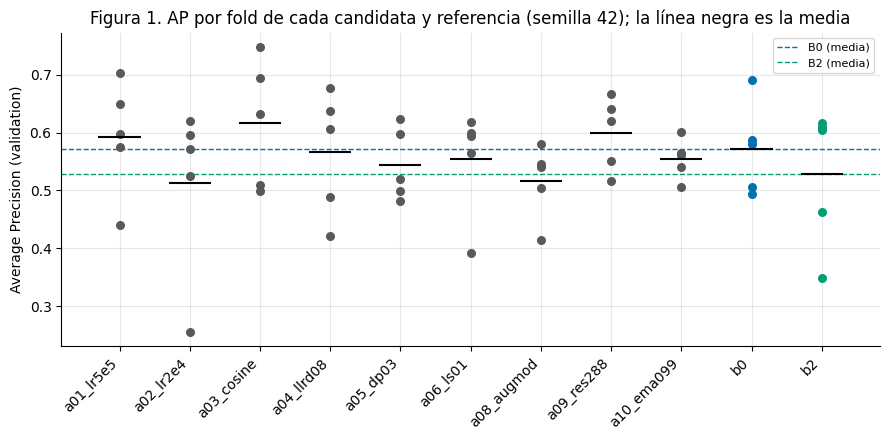

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = [c for c in CONFIGS if c in set(metrics["config_id"])]
for position, config in enumerate(ordered):
    values = metrics.loc[metrics["config_id"] == config, "ap"]
    ax.scatter([position] * len(values), values, color=COLORS.get(config, "0.35"), s=30, zorder=3)
    ax.hlines(values.mean(), position - 0.3, position + 0.3, color="black", lw=1.5, zorder=4)
for reference in ("b0", "b2"):
    ax.axhline(metrics.loc[metrics["config_id"] == reference, "ap"].mean(), color=COLORS[reference], ls="--", lw=1, label=f"{reference.upper()} (media)")
ax.set_xticks(range(len(ordered)))
ax.set_xticklabels(ordered, rotation=45, ha="right")
ax.set_ylabel("Average Precision (validation)")
ax.set_title("Figura 1. AP por fold de cada candidata y referencia (semilla 42); la línea negra es la media")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "fig1_ap_por_fold.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Comparaciones frente a B0 y B2

El delta por fold es la candidata menos la referencia, con las mismas imágenes de validation. Se informan media, mínimo, máximo, desviación estándar muestral (solo descriptiva) y signos; un delta exactamente 0 no cuenta en ningún signo. La consistencia (mismo signo estricto en al menos 4 de 5 folds) se evalúa en ambas direcciones y solo con el AP; la ROC-AUC se reporta de forma descriptiva. Con cinco folds no se reporta p-valor ni intervalo de confianza. Se incluye B2 frente a B0 como referencia.

In [6]:
summary = pd.read_csv(OUTPUTS["delta_summary"])
ap_summary = summary[summary["metrica"] == "AP"].rename(columns={"folds_positivos": "folds +", "folds_negativos": "folds -", "folds_cero": "folds 0"})
display(ap_summary[["comparacion", "media", "minimo", "maximo", "folds +", "folds -", "folds 0", "veredicto"]].round(4).set_index("comparacion"))
auc_summary = summary[summary["metrica"] == "ROC-AUC"].set_index("comparacion")
print("ΔROC-AUC medio frente a B0 (descriptivo):")
display(auc_summary.loc[[c for c in auc_summary.index if c.endswith("__vs_b0")], ["media", "minimo", "maximo"]].round(4))

,media,minimo,maximo,folds +,folds -,folds 0,veredicto
comparacion,,,,,,,
a01_lr5e5__vs_b0,0.0217,-0.1407,0.1035,4,1,0,mejor_consistente
a01_lr5e5__vs_b2,0.0648,-0.0335,0.2496,3,2,0,no_consistente
a02_lr2e4__vs_b0,-0.0579,-0.2509,0.0390,2,3,0,no_consistente
a02_lr2e4__vs_b2,-0.0148,-0.3543,0.1776,2,3,0,no_consistente
a03_cosine__vs_b0,0.0452,-0.0713,0.1272,4,1,0,mejor_consistente
a03_cosine__vs_b2,0.0883,0.0238,0.1505,5,0,0,mejor_consistente
a04_llrd08__vs_b0,-0.0052,-0.1598,0.1009,2,3,0,no_consistente
a04_llrd08__vs_b2,0.0379,-0.0426,0.1416,3,2,0,no_consistente
a05_dp03__vs_b0,-0.0275,-0.2093,0.1181,3,2,0,no_consistente


ΔROC-AUC medio frente a B0 (descriptivo):


,media,minimo,maximo
comparacion,,,
a01_lr5e5__vs_b0,-0.0142,-0.0708,0.0176
a02_lr2e4__vs_b0,-0.0460,-0.1200,-0.0023
a03_cosine__vs_b0,-0.0027,-0.0612,0.0263
a04_llrd08__vs_b0,-0.0175,-0.0766,0.0335
a05_dp03__vs_b0,-0.0186,-0.0399,0.0286
a06_ls01__vs_b0,-0.0142,-0.0276,0.0005
a08_augmod__vs_b0,-0.0260,-0.0817,0.0072
a09_res288__vs_b0,-0.0021,-0.0255,0.0122
a10_ema099__vs_b0,-0.0242,-0.0447,0.0024


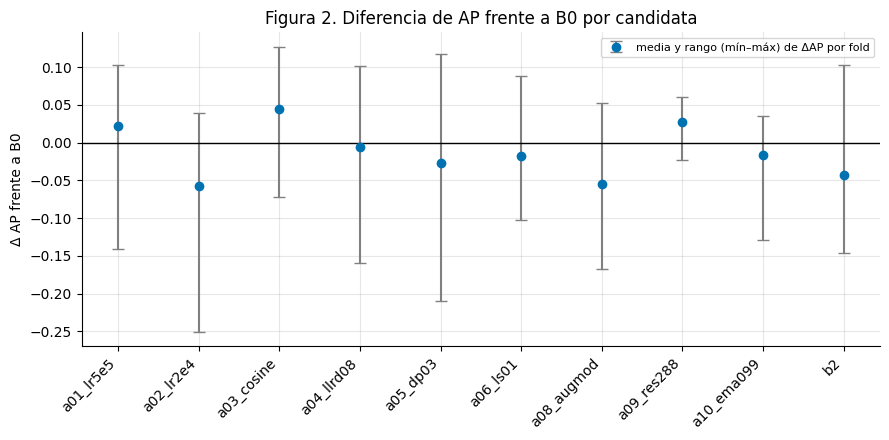

In [7]:
vs_b0 = ap_summary[ap_summary["comparacion"].str.endswith("__vs_b0")].copy()
vs_b0["candidata"] = vs_b0["comparacion"].str.replace("__vs_b0", "", regex=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(vs_b0))
ax.errorbar(positions, vs_b0["media"], yerr=[vs_b0["media"] - vs_b0["minimo"], vs_b0["maximo"] - vs_b0["media"]],
            fmt="o", color="#0072B2", ecolor="0.5", capsize=4, label="media y rango (mín–máx) de ΔAP por fold")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(positions)
ax.set_xticklabels(vs_b0["candidata"], rotation=45, ha="right")
ax.set_ylabel("Δ AP frente a B0")
ax.set_title("Figura 2. Diferencia de AP frente a B0 por candidata")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "fig2_delta_ap_vs_b0.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Selección del finalista

Aplicación mecánica de `seleccion_del_finalista`: son elegibles las candidatas con ΔROC-AUC medio frente a B0 mayor o igual que -0.02; el finalista es la elegible con mayor AP medio entre los 5 folds; si hay empate (diferencia menor que 0.005 respecto del máximo) decide la mayor ROC-AUC media y luego el menor id. Una candidata con algún fold fallido queda descartada y cuenta como probada. Si ninguna es elegible no hay confirmación ni ganadora y se aplica `sin_ganadora`.

In [8]:
selection = json.loads(OUTPUTS["selection"].read_text(encoding="utf-8"))
print(f"Protocolo idéntico al commit {selection['protocolo']['commit_de_referencia']}: {selection['protocolo']['idéntico_al_commit']}")
print(f"Corridas: {selection['conteo']['completadas']} completadas, {selection['conteo']['fallidas']} fallidas | umbrales: {selection['regla']['umbrales_leidos_del_texto']}")

table = pd.DataFrame(selection["candidatas"]).set_index("id")
display(table[["ap_medio", "roc_auc_medio", "delta_auc_medio_vs_b0", "elegible", "descartada", "motivo"]].round(4))
print(f"Elegibles: {selection['elegibles']}")
print(f"AP medio máximo: {selection['ap_maximo']} | en empate: {selection['en_empate']}")
print(f"Finalista: {selection['finalista']} | el desempate cambia el finalista: {selection['el_desempate_cambia_el_finalista']}")
print(f"Consecuencia: {selection['consecuencia']}")

Protocolo idéntico al commit 7d48f86: True
Corridas: 45 completadas, 0 fallidas | umbrales: {'delta_auc_minimo': -0.02, 'empate_ap': 0.005}


,ap_medio,roc_auc_medio,delta_auc_medio_vs_b0,elegible,descartada,motivo
id,,,,,,
a01_lr5e5,0.5933,0.8827,-0.0142,True,False,
a02_lr2e4,0.5137,0.8510,-0.0460,False,False,ΔROC-AUC medio frente a B0 < -0.02
a03_cosine,0.6168,0.8942,-0.0027,True,False,
a04_llrd08,0.5664,0.8795,-0.0175,True,False,
a05_dp03,0.5441,0.8784,-0.0186,True,False,
a06_ls01,0.5538,0.8828,-0.0142,True,False,
a08_augmod,0.5171,0.8709,-0.0260,False,False,ΔROC-AUC medio frente a B0 < -0.02
a09_res288,0.5993,0.8948,-0.0021,True,False,
a10_ema099,0.5547,0.8727,-0.0242,False,False,ΔROC-AUC medio frente a B0 < -0.02


Elegibles: ['a03_cosine', 'a09_res288', 'a01_lr5e5', 'a04_llrd08', 'a06_ls01', 'a05_dp03']
AP medio máximo: 0.6167614466855524 | en empate: ['a03_cosine']
Finalista: a03_cosine | el desempate cambia el finalista: False
Consecuencia: hay finalista: se generan los 30 comandos de confirmación (comandos_confirmacion.json)


## 7. Comandos de confirmación

Solo si hay finalista: 30 comandos (finalista, B0 y B2; semillas 43 y 44; cinco folds) generados por sustitución mecánica de la plantilla del protocolo y verificados contra ella. La decisión usa solo las semillas 43 y 44. El autor debe comprobar que coinciden con la plantilla antes de correr.

In [9]:
if not OUTPUTS["commands"].exists():
    print("No hay finalista: no se genera comandos_confirmacion.json (75 -> 45 corridas).")
else:
    payload = json.loads(OUTPUTS["commands"].read_text(encoding="utf-8"))
    print(f"Finalista: {payload['finalista']} | flags: {payload['flags_del_finalista']} | comandos: {payload['total']}")
    display(pd.Series(payload["verificacion_contra_la_plantilla"], name="cumple"))
    print(payload["comandos"][0]["comando"])

Finalista: a03_cosine | flags: --lr-schedule warmup_cosine --warmup-epochs 1 --cosine-epochs 15 --lr-min 1e-6 | comandos: 30


30 comandos (3 configuraciones x 2 semillas x 5 folds)                        True
comandos y salidas únicos                                                     True
sin espacios dobles ni espacios al final                                      True
todas las combinaciones id x semilla x fold                                   True
cada comando coincide con la plantilla y con los flags de su configuración    True
Name: cumple, dtype: bool

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_agente --seed 43 --checkpoint-metric val_roc_auc --lr-schedule warmup_cosine --warmup-epochs 1 --cosine-epochs 15 --lr-min 1e-6 --split-csv configs/splits/cv_folds_e2.csv --fold 0 --output-dir results/classification/r7_optimizacion/agente/confirmacion/a03_cosine/seed_43/fold_0


## 8. Confirmación del finalista (semillas 43 y 44)

El finalista de la etapa 1 (`seleccion_finalista.json`), B0 y B2 se corren con las semillas 43 y 44 en los cinco folds: 30 corridas en `agente/confirmacion/`. La decisión usa solo estas dos semillas; la semilla 42 no entra en la regla de elección. Los comandos son los de `comandos_confirmacion.json` (sección 7).

### 8.1 Carga y verificación

Esta sección solo lee archivos. Además de las comprobaciones de la sección 3 (configuración registrada igual al comando, partición, pesos de clase con el α de cada configuración, sin test, AP y ROC-AUC recalculables), comprueba que los 30 comandos coinciden con la plantilla del protocolo y con su regeneración mecánica, que semillas y folds son 43/44 y 0-4, que no hay NaN y que la época del checkpoint está dentro del rango. Si falta una corrida o falla una comprobación, no se escribe ningún resultado. Las tablas se escriben en `agente/confirmacion/analisis/` mediante `src/classification/agente_confirmacion_analysis.py`; si ya existen, solo se leen.

In [10]:
from src.classification import agente_confirmacion_analysis as a2  # toda la lógica de la confirmación está en este módulo

CONF_OUT = PROJECT_ROOT / a2.CONFIRMATION_REL / a2.ANALYSIS_NAME
CONF_OUTPUTS = {key: CONF_OUT / name for key, name in a2.OUTPUT_FILES.items()}
CONF_COMMANDS = json.loads((PROJECT_ROOT / a2.STAGE1_ANALYSIS_REL / a2.COMMANDS_NAME).read_text(encoding="utf-8"))
FINALIST_ID = CONF_COMMANDS["finalista"]

RUN_TRAINING = False  # se declara de nuevo para proteger esta sección: True lanza las corridas de la confirmación que falten (solo en Falcon); False solo las lista
done = [c["id"] for c in CONF_COMMANDS["comandos"] if (PROJECT_ROOT / c["salida"] / "validation_metrics.json").exists()]
print(f"Finalista: {FINALIST_ID} | corridas de la confirmación con resultados: {len(done)} de {len(CONF_COMMANDS['comandos'])}")

if not RUN_TRAINING:
    print("RUN_TRAINING = False: no se inicia ningún entrenamiento.")
else:
    for item in CONF_COMMANDS["comandos"]:
        output_dir = PROJECT_ROOT / item["salida"]
        print("=" * 80)
        print(f"{item['id']} -> {item['salida']}/")
        if output_dir.exists() and any(output_dir.iterdir()):
            print("Omitida: la carpeta ya contiene archivos y no se sobrescribe. Si una corrida quedó incompleta, revísela o muévala manualmente.")
            continue
        process = subprocess.Popen([sys.executable, *shlex.split(item["comando"])[1:]], cwd=PROJECT_ROOT,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1)
        try:
            for line in process.stdout:
                print(line, end="")
        except KeyboardInterrupt:
            process.terminate()
            raise
        if process.wait() != 0:
            raise RuntimeError(f"La corrida {item['id']} terminó con error (código {process.returncode}).")

Finalista: a03_cosine | corridas de la confirmación con resultados: 30 de 30
RUN_TRAINING = False: no se inicia ningún entrenamiento.


In [11]:
missing_conf = [c["salida"] for c in CONF_COMMANDS["comandos"] if not (PROJECT_ROOT / c["salida"]).exists()]
require(not missing_conf, "Faltan carpetas de la confirmación (git pull o completar las corridas):\n" + "\n".join(missing_conf))

if not any(path.exists() for path in CONF_OUTPUTS.values()):
    exit_code, _ = a2.run_analysis(PROJECT_ROOT, verbose=False)
    require(exit_code == 0, "El análisis no se escribió: hay comprobaciones fallidas (ejecute `python -m src.classification.agente_confirmacion_analysis`).")
else:
    require(all(path.exists() for path in CONF_OUTPUTS.values()), "confirmacion/analisis/ está incompleta; revise la carpeta antes de continuar.")

conf_verification = pd.read_csv(CONF_OUTPUTS["verification"])
print(f"Comprobaciones: {len(conf_verification)} | fallidas: {int((~conf_verification['ok']).sum())}")
display(conf_verification.groupby("comprobacion", sort=False)["ok"].agg(corridas="size", todas_ok="all"))

Comprobaciones: 1129 | fallidas: 0


,corridas,todas_ok
comprobacion,,
incluye la enmienda E1,1,True
idéntico al del commit 7d48f86,1,True
"30 corridas = 3 configuraciones x semillas 43 y 44 x folds 0..4, sin repetir",1,True
el finalista de comandos_confirmacion.json = el de seleccion_finalista.json de la etapa 1,1,True
el finalista es una candidata del protocolo,1,True
los flags del finalista = los de la candidata en el protocolo,1,True
"las configuraciones de los comandos son el finalista, B0 y B2",1,True
30 comandos (3 configuraciones x 2 semillas x 5 folds),1,True
comandos y salidas únicos,1,True


### 8.2 AP y ROC-AUC por fold y deltas

La métrica de cada fold es el promedio de las semillas 43 y 44 de esa configuración (criterio de checkpoint del protocolo: máximo `val_roc_auc`). El delta por fold es el finalista menos la referencia, con las mismas imágenes de validation. Se informan media, desviación estándar muestral (n-1, descriptiva), mínimo, máximo y signos; el protocolo no admite intervalo de confianza ni p-valor con 5 folds, y no se calculan.

In [12]:
conf_by_fold = pd.read_csv(CONF_OUTPUTS["by_fold"])
for column, title in (("ap_promedio_semillas", "AP"), ("roc_auc_promedio_semillas", "ROC-AUC")):
    conf_table = conf_by_fold.pivot(index="fold", columns="config_id", values=column)[[FINALIST_ID, "b0", "b2"]]
    conf_table.loc["media"] = conf_table.mean()
    print(f"{title} por fold (promedio de las semillas 43 y 44)")
    display(conf_table.round(4))

conf_summary = pd.read_csv(CONF_OUTPUTS["delta_summary"])
display(conf_summary[["comparacion", "metrica", "media", "desv_est_muestral", "minimo", "maximo", "folds_positivos", "folds_negativos", "folds_cero", "veredicto"]].round(4))

AP por fold (promedio de las semillas 43 y 44)


config_id,a03_cosine,b0,b2
fold,,,
0,0.5626,0.5316,0.5020
1,0.6490,0.5680,0.6215
2,0.6701,0.7248,0.7018
3,0.6323,0.6142,0.5377
4,0.5126,0.5653,0.5632
media,0.6053,0.6008,0.5853


ROC-AUC por fold (promedio de las semillas 43 y 44)


config_id,a03_cosine,b0,b2
fold,,,
0,0.8530,0.8132,0.8164
1,0.8917,0.8838,0.9139
2,0.9354,0.9465,0.9364
3,0.8999,0.9065,0.8774
4,0.8742,0.8933,0.8931
media,0.8908,0.8887,0.8874


,comparacion,metrica,media,desv_est_muestral,minimo,maximo,folds_positivos,folds_negativos,folds_cero,veredicto
0,a03_cosine__vs_b0,AP,0.0046,0.0581,-0.0547,0.0810,3,2,0,no_consistente
1,a03_cosine__vs_b0,ROC-AUC,0.0022,0.0232,-0.0192,0.0398,2,3,0,NaN
2,a03_cosine__vs_b2,AP,0.0201,0.0611,-0.0506,0.0947,3,2,0,no_consistente
3,a03_cosine__vs_b2,ROC-AUC,0.0034,0.0257,-0.0222,0.0366,2,3,0,NaN


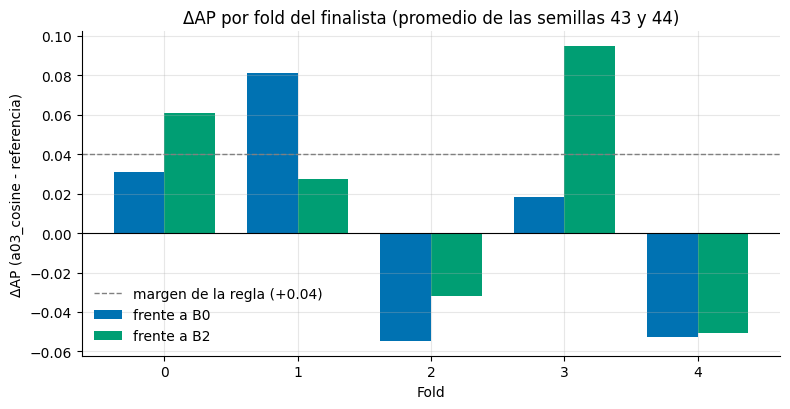

In [13]:
conf_deltas = pd.read_csv(CONF_OUTPUTS["delta_by_fold"])
conf_verdict = json.loads(CONF_OUTPUTS["verdict"].read_text(encoding="utf-8"))
margin = next(c["umbral"] for c in conf_verdict["regla"]["umbrales_leidos_del_texto"] if c["id"] == "C1")  # margen de ΔAP de la regla

fig, ax = plt.subplots(figsize=(8, 4.2))
ap_deltas = conf_deltas[conf_deltas["metrica"] == "AP"].pivot(index="fold", columns="segunda", values="delta")
width = 0.38
for offset, reference in ((-width / 2, "b0"), (width / 2, "b2")):
    ax.bar(ap_deltas.index + offset, ap_deltas[reference], width=width, color=COLORS[reference], label=f"frente a {reference.upper()}")
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(margin, color="gray", linestyle="--", linewidth=1, label=f"margen de la regla (+{margin})")
ax.set_xticks(range(N_FOLDS))
ax.set_xlabel("Fold")
ax.set_ylabel(f"ΔAP ({FINALIST_ID} - referencia)")
ax.set_title("ΔAP por fold del finalista (promedio de las semillas 43 y 44)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 8.3 Regla de elección

Aplicación literal de `regla_de_eleccion` con los umbrales leídos del texto del protocolo: el finalista es ganador solo si cumple las seis condiciones (ΔAP medio ≥ +0.04, ΔAP > 0 en al menos 4 de 5 folds y ΔROC-AUC medio ≥ -0.02, cada una frente a B0 y frente a B2). Si alguna falla, no hay ganadora y R8 se mantiene con B0 y B2. Los valores se comparan sin redondear; la columna `margen` es el valor menos el umbral.

In [14]:
display(pd.DataFrame(conf_verdict["condiciones"])[["id", "magnitud", "referencia", "valor", "umbral", "cumple", "margen"]].round(4))
print(f"Veredicto mecánico: {conf_verdict['veredicto_mecanico']} | condiciones incumplidas: {conf_verdict['condiciones_incumplidas']}")
print(f"Consecuencia según el protocolo: {conf_verdict['consecuencia']}")
print(f"Corridas: etapa 1 = {conf_verdict['conteo']['corridas_etapa_1']}, confirmación = {conf_verdict['conteo']['corridas_confirmacion']} "
      f"| configuraciones nuevas probadas: {conf_verdict['conteo']['configuraciones_nuevas_probadas']} (más B0 y B2) "
      f"| fallidas o descartadas: {conf_verdict['conteo']['corridas_fallidas_o_descartadas']}")

,id,magnitud,referencia,valor,umbral,cumple,margen
0,C1,ΔAP medio,B0,0.0046,0.04,False,-0.0354
1,C2,ΔAP medio,B2,0.0201,0.04,False,-0.0199
2,C3,folds con ΔAP > 0,B0,3.0000,4.00,False,-1.0000
3,C4,folds con ΔAP > 0,B2,3.0000,4.00,False,-1.0000
4,C5,ΔROC-AUC medio,B0,0.0022,-0.02,True,0.0222
5,C6,ΔROC-AUC medio,B2,0.0034,-0.02,True,0.0234


Veredicto mecánico: sin_ganadora | condiciones incumplidas: ['C1', 'C2', 'C3', 'C4']
Consecuencia según el protocolo: si el finalista no cumple alguna condición, o no hay finalista, el agente no propone modelo: R8 se mantiene con B0 y B2 (results/classification/r7_optimizacion/cierre_seleccion/protocolo_r8_congelado.json, 6 modelos). No se sustituye por B2 ni se elige otra candidata. Se reporta: número de configuraciones y de corridas probadas, la tabla completa (incluidas las descartadas y las peores), el finalista con su resultado de confirmación, los resultados de B2 frente a B0 con tres semillas, y que la prueba tiene poca potencia (error estándar de ΔAP ≈ 0.047 con una semilla), por lo que no se concluye que las técnicas no funcionen.
Corridas: etapa 1 = 45, confirmación = 30 | configuraciones nuevas probadas: 9 (más B0 y B2) | fallidas o descartadas: 0


### 8.4 B2 frente a B0 con tres semillas (descriptivo)

Contraste descriptivo que el protocolo pide informar (`sin_ganadora`): B2 frente a B0 con la semilla 42 (corridas existentes de `robustez_e2`) más las semillas 43 y 44. El protocolo no define cómo combinar las semillas, y **no se elige una lectura**: se muestran tres. A: Δ por fold sobre el promedio de las tres semillas. B: Δ por fold dentro de cada semilla. C: Δ por fold sobre el promedio de 43 y 44 (la base de la regla de elección). En el veredicto, `mejor_consistente` significa B2 por encima de B0 en al menos 4 de 5 folds de AP y `peor_consistente`, lo contrario. La lectura que se use debe decidirla el autor antes de interpretar.

In [15]:
contrast = pd.read_csv(CONF_OUTPUTS["contrast_summary"])
display(contrast[["lectura", "semillas", "metrica", "media", "desv_est_muestral", "minimo", "maximo", "folds_positivos", "folds_negativos", "folds_cero", "veredicto"]].round(4))
for point in conf_verdict["puntos_pendientes_de_decision"]:
    print(f"- Pendiente de decisión: {point['punto']}")

,lectura,semillas,metrica,media,desv_est_muestral,minimo,maximo,folds_positivos,folds_negativos,folds_cero,veredicto
0,A_promedio_por_fold_de_las_3_semillas,"42,43,44",AP,-0.0247,0.0301,-0.0684,0.0073,1,4,0,peor_consistente
1,A_promedio_por_fold_de_las_3_semillas,"42,43,44",ROC-AUC,-0.0151,0.0179,-0.0329,0.0111,1,4,0,NaN
2,B_por_semilla,42,AP,-0.0431,0.1056,-0.1460,0.1035,2,3,0,no_consistente
3,B_por_semilla,42,ROC-AUC,-0.0427,0.0395,-0.1050,0.0003,1,4,0,NaN
4,B_por_semilla,43,AP,-0.0168,0.1074,-0.1939,0.0586,3,2,0,no_consistente
5,B_por_semilla,43,ROC-AUC,0.0016,0.0274,-0.0342,0.0347,2,2,1,NaN
6,B_por_semilla,44,AP,-0.0143,0.0659,-0.1089,0.0486,2,3,0,no_consistente
7,B_por_semilla,44,ROC-AUC,-0.0041,0.0268,-0.0283,0.0391,1,4,0,NaN
8,C_promedio_por_fold_de_las_semillas_43_y_44,"43,44",AP,-0.0155,0.0472,-0.0765,0.0536,1,4,0,peor_consistente
9,C_promedio_por_fold_de_las_semillas_43_y_44,"43,44",ROC-AUC,-0.0012,0.0216,-0.0291,0.0301,2,3,0,NaN


- Pendiente de decisión: B2 frente a B0 con tres semillas: cómo combinar las semillas 42, 43 y 44
- Pendiente de decisión: Corrida fallida o ausente en la confirmación
- Pendiente de decisión: Margen exacto sobre un umbral


## 9. Limitaciones

- E2 es estratificada y no por paciente (no hay identificadores de paciente): puede sobreestimar, y los cinco folds no son independientes entre sí porque comparten imágenes de entrenamiento.
- Una semilla por fold en la etapa 1: no se separa la variabilidad por semilla de la variabilidad por fold. Cada fold de validation tiene 21 o 22 positivas operacionales, de modo que el AP por fold es ruidoso; con una semilla, el error estándar de ΔAP es del orden del margen de 0.04 de la regla de elección (cálculo propio del protocolo, por verificar).
- El AP medio del finalista es el máximo de nueve estimaciones ruidosas: sesgo al alza (selección del ganador). Con la regla de signo de 4 de 5 folds y nueve candidatas, la probabilidad de que alguna la cumpla por azar frente a B0 es de ≈ 0.85 bajo la hipótesis nula del protocolo, un cálculo aproximado (los folds no son independientes).
- Las 1000 imágenes de E2 incluyen las 200 de validation de E1 con las que se seleccionaron B2 y el criterio de checkpoint: E2 no es independiente de esa selección.
- El efecto de cada factor se mide solo desde la base B0 y sin combinaciones: no se detectan interacciones. El early stopping por pérdida ponderada puede detener el entrenamiento antes del máximo de AUC; no se modifica porque el criterio está fijo.
- Las categorías 6 y 7 están agrupadas en la clase positiva operacional; la categoría 6 no es malignidad histológica. Varias fuentes del protocolo están marcadas [CITA POR VERIFICAR].
- Solo se usan archivos de validation; test no interviene. La estimación válida del desempeño es la de test en R8.
- Confirmación: dos semillas por fold, con las mismas imágenes con las que se eligió el finalista. El AP de confirmación del finalista sigue siendo optimista aunque la decisión no use la semilla 42. Con cinco folds no se informa intervalo de confianza ni p-valor, y los cinco folds no son independientes entre sí.

## 10. Interpretación de resultados

*Pendiente.* Esta sección se redacta solo después de ejecutar el notebook, con las cifras de los archivos de `agente/analisis_etapa1/` y `agente/confirmacion/analisis/` y sin añadir reglas a las del protocolo.